### **Student Information**
GitHub ID: Chiwa42

Kaggle name: chiwa

Final Kaggle Private Leaderboard: **score 0.5441; rank 94**. 

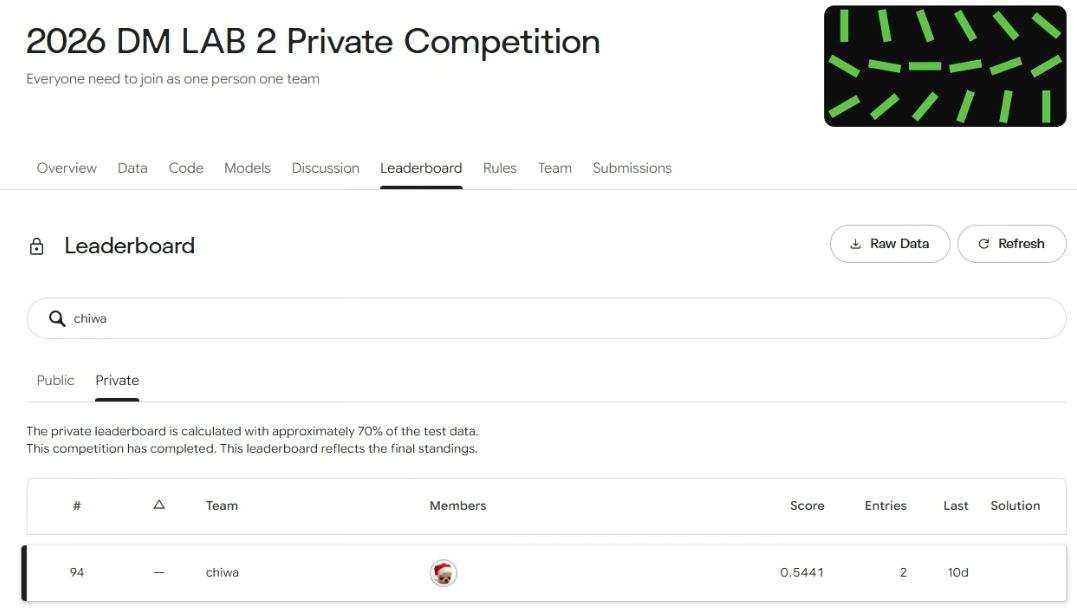

*The original screenshot is also retained at pics/pic_ranking.png for submission.*

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

# Project Report

## 1. Model Development

### 1.1 Preprocessing Steps

The official competition files contain 4,800 posts: 3,360 labeled training rows and 1,440 test rows. The six classes are anger (674), disgust (454), fear (288), joy (875), sadness (628), and surprise (441). Posts are joined to the official split and training labels by **post_id**, with one-to-one ID checks. The labels in the sample submission are placeholders and are not used as targets.

Text preprocessing decodes HTML entities, applies Unicode NFKC normalization, and collapses whitespace. Raw text is retained. Case, punctuation, negation, hashtags, and emoji remain available in **text_clean**; the individual feature extractors then apply their own tokenization and lowercasing.

There are 50 extra training rows sharing normalized text, 16 normalized training-text groups with multiple labels, and 59 distinct normalized texts shared by the official training and test sets. All official rows and labels are retained. For internal validation, groups are defined by normalized, case-folded text, preventing identical normalized text from crossing a fit/validation boundary. This protects against exact-duplicate leakage but does not detect every paraphrase or near-duplicate.

The first experiment uses a fixed stratified group split of 2,687 fit rows and 673 validation rows (seed 42). The upgrade is selected using five-fold StratifiedGroupKFold over the labeled training set, also with seed 42. TF-IDF vocabulary and IDF are fitted separately within each fold. Kaggle test labels are unavailable and are not used in selection.

### 1.2 Feature Engineering Steps

Three lexical baselines are compared: word TF-IDF unigrams/bigrams, character TF-IDF with character-within-word n-grams of lengths 3-5, and their concatenation. All use min_df=2 and sublinear term frequency. Stopwords are retained so that potentially useful emotion and negation cues are not deliberately removed. Concatenated vectors are globally L2-normalized.

The semantic upgrade uses the locally cached **sentence-transformers/all-MiniLM-L6-v2** encoder with frozen weights. Each post becomes a normalized 384-dimensional vector. Encoding is performed locally on CPU; no external LLM API is used to obtain predictions. Content-addressed caches include the model identifier, ordered post IDs, text, and normalization setting, avoiding accidental reuse of another dataset's vectors.

For hybrid features, a normalized character TF-IDF vector is concatenated with a weighted MiniLM vector, then the combined row is L2-normalized. The encoder is frozen, so precomputing its vectors for all posts does not learn corpus vocabulary, targets, or IDF. The trainable TF-IDF components and classifiers still fit only their respective training folds.

### 1.3 Explanation of the Model and Results

The initial baseline compares three lexical feature sets with a Linear SVM at C=1.0, with and without balanced class weights. On the fixed grouped holdout, character TF-IDF without class weighting is best: macro F1 **0.5101**, micro F1 **0.5349**, and weighted F1 **0.5290**. Its first successful Kaggle submission received **0.4947**, as shown in the leaderboard supplied during development. A validation score slightly above 0.5 therefore did not guarantee a Kaggle score above the competition baseline.

A pilot compares semantic-only Logistic Regression and Linear SVM models, with and without balanced class weights, against a character/semantic hybrid. Semantic-only features did not improve on the lexical baseline: the best pilot semantic-only macro F1 was **0.4686**. The unweighted hybrid SVM improved the same holdout score to **0.5347**. Balanced class weighting was not automatically beneficial and was not retained for the final upgrade.

The subsequent five-fold grouped comparison uses a small declared grid:

| Configuration | Embedding weight | C | Mean macro F1 | Fold SD |
| --- | ---: | ---: | ---: | ---: |
| hybrid_w1_c1 | 1 | 1 | 0.5436 | 0.0114 |
| hybrid_w2_c1 | 2 | 1 | 0.5375 | 0.0177 |
| hybrid_w0.5_c1 | 0.5 | 1 | 0.5373 | 0.0131 |
| hybrid_w1_c3 | 1 | 3 | 0.5239 | 0.0106 |
| char_c0.3 | 0 | 0.3 | 0.5123 | 0.0140 |
| char_c1 | 0 | 1 | 0.4963 | 0.0107 |

The selected configuration is **hybrid_w1_c1**: equal character/semantic weights, C=1.0, and no class weighting. Its mean macro F1 is **0.5436**, with fold-to-fold SD **0.0114**, versus **0.4963** for the original character C=1.0 baseline under the same five-fold protocol. The absolute gain is **0.0473**, or **4.73 percentage points**, and the hybrid improved on that reference in **5/5 folds**.

The SD describes variation between folds; it is not a confidence interval. These folds also select the configuration, so the winning CV score is not an unbiased final performance estimate. The competition page says **Mean F1 Score** without an explicit averaging formula; macro F1 is the provisional selection objective, while micro and weighted F1 are also reported. Mean fold F1 and the pooled out-of-fold report are shown separately because they need not be numerically identical.

After selection, TF-IDF and the classifier are refitted on all 3,360 labeled posts. The exported CSV preserves sample-submission ID order and has exactly two columns, **id,label**. The downloaded sample uses **post_id**, whereas the competition page and submission validator require **id**, so the output key is explicitly renamed. The original baseline CSV is retained separately from **submission_hybrid_v1.csv**.

**Observed Kaggle results (snapshot supplied on November 15, 2026):** the baseline scored **0.4947**, and **submission_hybrid_v1.csv** scored **0.5420**, an observed improvement of **0.0473** (4.73 percentage points). The displayed current rank was **27 out of 30 teams**. This snapshot is provisional and is not presented as the final Private Leaderboard result. The November 15 snapshot above is retained as development history.

**Final Private Leaderboard result (screenshot supplied on November 24, 2026):** score **0.5441**, rank **94**. The screenshot shows the Private tab selected and a completed-competition notice identifying the leaderboard as the final standings. It is displayed in the Student Information section. The filtered view does not show the total number of ranked teams, so no rank percentile or ranking-based grade is inferred here. The private score is reported separately from the earlier development leaderboard score of 0.5420.

### 1.4 AI Prompts and Adopted Decisions

AI support covered concept clarification, data and code organization, implementation/debugging support, and editing the presentation of measured results. Topics included TF-IDF, semantic embeddings, grouped validation, regularization, and F1 interpretation.

The table summarizes related requests in English. It is an activity summary of the original development conversation, not a verbatim English prompt transcript.

| Request category | Explanation or organizational support | Evidence used to retain or reject the suggestion |
| --- | --- | --- |
| Review the downloaded files and explain the next steps. | Clarify how the text, official split, labels, and sample submission relate. | One-to-one ID joins, split membership checks, and preserved submission order. |
| Locate and interpret the evaluation requirements. | Explain the Mean F1 description and the required CSV schema. | The saved competition page; macro, micro, and weighted F1 are reported because the averaging formula was not explicit. |
| Review the outputs and explain model-comparison results. | Clarify duplicate leakage, class weighting, lexical/semantic representations, and grouped validation. | Fixed-holdout and grouped-CV results; semantic-only models were not retained as the final model. |
| Diagnose the submission ID-column error. | Clarify the internal join key and the external output key. | The Kaggle validator requires **id,label**, while the downloaded sample uses **post_id**. |
| Discuss options after the baseline score of 0.4947. | Explain complementary lexical and semantic information and organize a controlled comparison. | The hybrid configuration was retained based on grouped CV; its later Kaggle score was **0.5420**. |
| Organize the experiment records and submission items. | Structure the results, method descriptions, and file checklist. | Recorded metrics and submission files; the development snapshot and confirmed final private result are identified separately. |

Computational results come from executed local Python code and recorded Kaggle submissions. The report distinguishes suggestions from measured outcomes, retains unsuccessful alternatives, and states the limits of the evaluation protocol.


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
# Competition preprocessing: load official splits and create a leakage-aware holdout.
# Run this notebook with the same Python environment as the Master notebook.
import html
import json
import unicodedata
from pathlib import Path

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
DATA_CANDIDATES = [
    Path("../2026-dm-lab-2-private-competition"),
    Path("2026-dm-lab-2-private-competition"),
    Path("data/competition"),
]
DATA_DIR = next((p.resolve() for p in DATA_CANDIDATES
                 if (p / "final_posts.json").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Place the downloaded competition folder beside DM2026-Lab2-Exercise.")

# Labels come from emotion.csv; sampleSubmission labels are placeholders only.
posts = pd.DataFrame(json.loads((DATA_DIR / "final_posts.json").read_text(encoding="utf-8")))
identification = pd.read_csv(DATA_DIR / "data_identification.csv", dtype={"post_id": "string"})
emotion_labels = pd.read_csv(DATA_DIR / "emotion.csv", dtype={"post_id": "string", "label": "string"})
sample_submission = pd.read_csv(DATA_DIR / "sampleSubmission.csv", dtype={"post_id": "string"})
posts["post_id"] = posts["post_id"].astype("string")

for name, table in [("posts", posts), ("identification", identification),
                    ("emotion", emotion_labels), ("sampleSubmission", sample_submission)]:
    if table["post_id"].isna().any() or not table["post_id"].is_unique:
        raise ValueError(f"{name}: post_id must be nonmissing and unique.")
if set(identification["set"]) != {"train", "test"}:
    raise ValueError("Unexpected values in the official split column.")
if set(posts["post_id"]) != set(identification["post_id"]):
    raise ValueError("Post IDs do not match the identification file.")
train_ids = set(identification.loc[identification["set"].eq("train"), "post_id"])
test_ids = set(identification.loc[identification["set"].eq("test"), "post_id"])
if set(emotion_labels["post_id"]) != train_ids:
    raise ValueError("emotion.csv must label exactly the official training IDs.")
if set(sample_submission["post_id"]) != test_ids:
    raise ValueError("The submission IDs must match the official test IDs.")

all_posts = identification.merge(posts, on="post_id", how="left", validate="one_to_one")
all_posts = all_posts.merge(emotion_labels, on="post_id", how="left", validate="one_to_one")
if all_posts["text"].isna().any():
    raise ValueError("Some posts have no text.")
train_posts = all_posts.loc[all_posts["set"].eq("train"), ["post_id", "text", "label"]].reset_index(drop=True)
# Preserve sampleSubmission's exact row order, with no placeholder target column.
test_posts = sample_submission[["post_id"]].merge(
    all_posts.loc[all_posts["set"].eq("test"), ["post_id", "text"]],
    on="post_id", how="left", sort=False, validate="one_to_one")
assert test_posts["post_id"].tolist() == sample_submission["post_id"].tolist()
assert train_posts["label"].notna().all()
assert all_posts.loc[all_posts["set"].eq("test"), "label"].isna().all()


def normalize_post(text):
    # Decode entities, normalize Unicode, and collapse whitespace while retaining
    # case, punctuation, negation, hashtags, and emoji as potential emotion cues.
    text = unicodedata.normalize("NFKC", html.unescape(text))
    return " ".join(text.split())


for frame in [train_posts, test_posts]:
    frame["text_clean"] = frame["text"].map(normalize_post)
    frame["text_group"] = frame["text_clean"].str.casefold()
    if frame["text_clean"].eq("").any():
        raise ValueError("Empty text after normalization; inspect it before modeling.")

LABELS = sorted(train_posts["label"].unique().tolist())
assert set(LABELS) == {"anger", "disgust", "fear", "joy", "sadness", "surprise"}
conflicting_groups = int((train_posts.groupby("text_group")["label"].nunique() > 1).sum())
shared_texts = set(train_posts["text_group"]) & set(test_posts["text_group"])
print("Official train/test rows:", len(train_posts), len(test_posts))
print("Emotion labels:", LABELS)
print("Extra training rows sharing normalized text:", int(train_posts["text_group"].duplicated().sum()))
print("Normalized training texts with multiple labels:", conflicting_groups)
print("Distinct normalized texts shared by official train/test:", len(shared_texts))

# Keep all official rows: repeated text may carry different emotion annotations.
# Group-aware validation prevents the same normalized text leaking across the
# internal fit/validation boundary. Official Kaggle test rows remain unchanged.
validation_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fit_indices, validation_indices = next(validation_splitter.split(
    train_posts["text_clean"], train_posts["label"], groups=train_posts["text_group"]))
fit_posts = train_posts.iloc[fit_indices].copy()
validation_posts = train_posts.iloc[validation_indices].copy()
assert set(fit_posts["text_group"]).isdisjoint(validation_posts["text_group"])

print("Internal fit/validation rows:", len(fit_posts), len(validation_posts))
print(pd.DataFrame({
    "all_train": train_posts["label"].value_counts(),
    "fit": fit_posts["label"].value_counts(),
    "validation": validation_posts["label"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int).to_string())
print(train_posts[["post_id", "text_clean", "label"]].head(3).to_string(index=False, max_colwidth=80))


Official train/test rows: 3360 1440
Emotion labels: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Extra training rows sharing normalized text: 50
Normalized training texts with multiple labels: 16
Distinct normalized texts shared by official train/test: 59
Internal fit/validation rows: 2687 673
          all_train  fit  validation
label                               
anger           674  539         135
disgust         454  363          91
fear            288  230          58
joy             875  700         175
sadness         628  502         126
surprise        441  353          88
post_id                       text_clean   label
f8bv5zh Thought it looked weird as well. disgust
q0rr1l9               Bear died in a pit disgust
p94rwgk            I have endured worse. sadness


## 2. Feature Engineering Steps

In [2]:
# Fit every text representation on the internal fit partition only.
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import Normalizer


def make_word_tfidf():
    # Keep stopwords/negation; min_df=2 limits one-off vocabulary.
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)


def make_char_tfidf():
    # Character pieces retain spelling, punctuation, and subword information.
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                           min_df=2, sublinear_tf=True)


feature_templates = {
    "word": make_word_tfidf(),
    "char": make_char_tfidf(),
    "word+char": Pipeline([
        ("union", FeatureUnion([("word", make_word_tfidf()),
                                ("char", make_char_tfidf())])),
        ("normalize", Normalizer()),  # match total L2 scale to the single-view cases
    ]),
}
fitted_feature_extractors = {}
feature_matrices = {}
feature_statistics = []
for name, template in feature_templates.items():
    extractor = clone(template)
    X_fit = extractor.fit_transform(fit_posts["text_clean"])
    X_validation = extractor.transform(validation_posts["text_clean"])
    fitted_feature_extractors[name] = extractor
    feature_matrices[name] = (X_fit, X_validation)
    feature_statistics.append({"features": name, "fit_rows": X_fit.shape[0],
                               "validation_rows": X_validation.shape[0],
                               "columns": X_fit.shape[1], "fit_nonzeros": X_fit.nnz})
print(pd.DataFrame(feature_statistics).to_string(index=False))


 features  fit_rows  validation_rows  columns  fit_nonzeros
     word      2687              673     6008         42823
     char      2687              673    23360        343975
word+char      2687              673    29368        386798


## 3. Model Implementation Steps

Fixed grouped-validation results (timings exclude feature extraction):
                run_id  features class_weight  accuracy  macro_f1  micro_f1  weighted_f1  fit_predict_seconds
         char_svm_none      char         none    0.5349    0.5101    0.5349       0.5290               0.1212
word+char_svm_balanced word+char     balanced    0.5171    0.5029    0.5171       0.5161               0.1270
    word+char_svm_none word+char         none    0.5230    0.5014    0.5230       0.5184               0.1202
     char_svm_balanced      char     balanced    0.5215    0.4997    0.5215       0.5192               0.1124
     word_svm_balanced      word     balanced    0.4740    0.4528    0.4740       0.4732               0.0386
         word_svm_none      word         none    0.4681    0.4434    0.4681       0.4635               0.1949
Selected baseline: char_svm_none
              precision    recall  f1-score   support

       anger      0.458     0.519     0.486       135
     disgust     

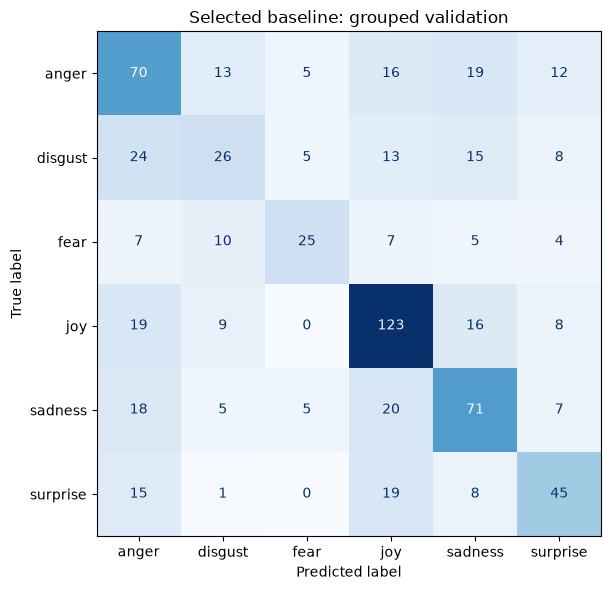

Submission saved: D:\chiwa42\TAICA_DM\Lab2\DM2026-Lab2-Exercise\competition_outputs\submission_baseline.csv
Submission shape: (1440, 2)
     id    label
xyzx9jp  sadness
l3vzzxt     fear
g680iug  sadness
m4t8bp6      joy
ai3al6e surprise
Predicted label counts: {'joy': 451, 'anger': 337, 'sadness': 255, 'surprise': 162, 'disgust': 141, 'fear': 94}
This is a baseline CSV; its validation score does not guarantee a Kaggle score.


In [3]:
# Compare a small, predefined CPU baseline set on the fixed grouped holdout.
import time
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.svm import LinearSVC

# The competition page says "Mean F1 Score" without an averaging formula.
# Macro F1 is a provisional selection objective; report micro/weighted F1 as well.
# All candidate selection uses the 673-row holdout, never Kaggle test labels.
baseline_runs = []
validation_models = {}
validation_predictions = {}
for feature_name, (X_fit, X_validation) in feature_matrices.items():
    for class_weight in [None, "balanced"]:
        weight_name = "none" if class_weight is None else class_weight
        run_id = f"{feature_name}_svm_{weight_name}"
        classifier = LinearSVC(C=1.0, class_weight=class_weight,
                               random_state=SEED, max_iter=5000)
        started = time.perf_counter()
        classifier.fit(X_fit, fit_posts["label"])
        prediction = classifier.predict(X_validation)
        validation_models[run_id] = classifier
        validation_predictions[run_id] = prediction
        baseline_runs.append({
            "run_id": run_id, "features": feature_name, "class_weight": weight_name,
            "accuracy": accuracy_score(validation_posts["label"], prediction),
            "macro_f1": f1_score(validation_posts["label"], prediction,
                                  labels=LABELS, average="macro", zero_division=0),
            "micro_f1": f1_score(validation_posts["label"], prediction,
                                  labels=LABELS, average="micro", zero_division=0),
            "weighted_f1": f1_score(validation_posts["label"], prediction,
                                     labels=LABELS, average="weighted", zero_division=0),
            "fit_predict_seconds": time.perf_counter() - started,
        })

baseline_results = pd.DataFrame(baseline_runs).sort_values(
    ["macro_f1", "run_id"], ascending=[False, True]).reset_index(drop=True)
print("Fixed grouped-validation results (timings exclude feature extraction):")
print(baseline_results.round(4).to_string(index=False))
best_baseline = baseline_results.iloc[0]
best_baseline_id = best_baseline["run_id"]
print("Selected baseline:", best_baseline_id)
print(classification_report(validation_posts["label"],
                            validation_predictions[best_baseline_id],
                            labels=LABELS, digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix(validation_posts["label"], validation_predictions[best_baseline_id], labels=LABELS),
    display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Selected baseline: grouped validation")
plt.tight_layout()
plt.show()

# Refit the selected configuration from scratch on all 3,360 labeled posts.
# A fresh cloned feature extractor learns vocabulary/IDF only from those posts.
final_baseline = Pipeline([
    ("features", clone(feature_templates[best_baseline["features"]])),
    ("classifier", clone(validation_models[best_baseline_id])),
])
final_baseline.fit(train_posts["text_clean"], train_posts["label"])
test_prediction = final_baseline.predict(test_posts["text_clean"])
# Kaggle's Submission Format requires id,label, although the downloaded sample
# uses post_id,label. Rename the output key while preserving its values/order.
submission_baseline = sample_submission[["post_id"]].rename(columns={"post_id": "id"}).copy()
submission_baseline["label"] = test_prediction
assert submission_baseline.columns.tolist() == ["id", "label"]
assert len(submission_baseline) == len(test_posts) == len(sample_submission)
assert submission_baseline["id"].tolist() == sample_submission["post_id"].tolist()
assert submission_baseline["id"].is_unique and submission_baseline.notna().all().all()
assert set(submission_baseline["label"]).issubset(LABELS)

OUTPUT_DIR = Path("competition_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
submission_path = OUTPUT_DIR / "submission_baseline.csv"
submission_baseline.to_csv(submission_path, index=False)
baseline_results.to_csv(OUTPUT_DIR / "baseline_validation_results.csv", index=False)
print("Submission saved:", submission_path.resolve())
print("Submission shape:", submission_baseline.shape)
print(submission_baseline.head().to_string(index=False))
print("Predicted label counts:", submission_baseline["label"].value_counts().to_dict())
print("This is a baseline CSV; its validation score does not guarantee a Kaggle score.")


## 4. Semantic Features and Local Pilot Comparison

Use the cached, frozen MiniLM encoder locally. Compare semantic-only and hybrid features on the original grouped holdout.


In [4]:
# LOCAL_SEMANTIC_UPGRADE: frozen local encoder, with content-addressed caches.
import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

import hashlib
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from huggingface_hub import snapshot_download
from sentence_transformers import SentenceTransformer
from scipy.sparse import csr_matrix, hstack
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import normalize
from sklearn.svm import LinearSVC

torch.set_num_threads(min(8, os.cpu_count() or 1))
SEMANTIC_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
OUTPUT_DIR = Path("competition_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
_semantic_encoder = None


def encode_competition_posts(frame, split_name):
    # The encoder is frozen: encoding validation/test inputs learns no corpus
    # vocabulary, IDF, or target information. IDs/text/order are part of the key.
    global _semantic_encoder
    payload = {"model": SEMANTIC_MODEL_ID, "ids": frame["post_id"].tolist(),
               "texts": frame["text_clean"].tolist(), "normalize": True}
    signature = hashlib.sha256(
        json.dumps(payload, ensure_ascii=False).encode("utf-8")).hexdigest()[:16]
    cache_path = OUTPUT_DIR / f"minilm_{split_name}_{signature}.npy"
    if cache_path.exists():
        vectors = np.load(cache_path)
        print(f"Loaded {split_name} encoder cache: {vectors.shape}")
    else:
        if _semantic_encoder is None:
            local_path = snapshot_download(repo_id=SEMANTIC_MODEL_ID,
                                           local_files_only=True)
            _semantic_encoder = SentenceTransformer(
                local_path, local_files_only=True, device="cpu")
        chunks = []
        for start in range(0, len(frame), 256):
            chunks.append(_semantic_encoder.encode(
                frame["text_clean"].iloc[start:start + 256].tolist(),
                batch_size=64, show_progress_bar=False,
                convert_to_numpy=True, normalize_embeddings=True))
            print(f"Encoded {split_name}: {min(start + 256, len(frame))}/{len(frame)}")
        vectors = np.vstack(chunks).astype("float32")
        np.save(cache_path, vectors)
    assert vectors.shape == (len(frame), 384) and np.isfinite(vectors).all()
    return vectors


semantic_train_vectors = encode_competition_posts(train_posts, "train")
pilot_char = clone(feature_templates["char"])
pilot_char_fit = pilot_char.fit_transform(fit_posts["text_clean"])
pilot_char_validation = pilot_char.transform(validation_posts["text_clean"])
pilot_semantic_fit = semantic_train_vectors[fit_indices]
pilot_semantic_validation = semantic_train_vectors[validation_indices]
pilot_hybrid_fit = normalize(hstack(
    [pilot_char_fit, csr_matrix(pilot_semantic_fit)], format="csr"))
pilot_hybrid_validation = normalize(hstack(
    [pilot_char_validation, csr_matrix(pilot_semantic_validation)], format="csr"))

# Pilot comparison uses the original fixed grouped holdout. The final model
# will instead be selected by five-fold grouped CV in the next cell.
pilot_settings = [
    ("char_reference", pilot_char_fit, pilot_char_validation,
     LinearSVC(C=1.0, random_state=SEED, max_iter=5000)),
    ("minilm_lr", pilot_semantic_fit, pilot_semantic_validation,
     LogisticRegression(C=4.0, max_iter=2000, random_state=SEED)),
    ("minilm_lr_balanced", pilot_semantic_fit, pilot_semantic_validation,
     LogisticRegression(C=4.0, class_weight="balanced", max_iter=2000, random_state=SEED)),
    ("minilm_svm", pilot_semantic_fit, pilot_semantic_validation,
     LinearSVC(C=1.0, random_state=SEED, max_iter=5000)),
    ("minilm_svm_balanced", pilot_semantic_fit, pilot_semantic_validation,
     LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)),
    ("char_minilm_svm", pilot_hybrid_fit, pilot_hybrid_validation,
     LinearSVC(C=1.0, random_state=SEED, max_iter=5000)),
    ("char_minilm_svm_balanced", pilot_hybrid_fit, pilot_hybrid_validation,
     LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)),
]
semantic_pilot_rows = []
for run_id, X_fit, X_validation, estimator in pilot_settings:
    started = time.perf_counter()
    estimator.fit(X_fit, fit_posts["label"])
    predicted = estimator.predict(X_validation)
    semantic_pilot_rows.append({
        "run_id": run_id,
        **{f"{average}_f1": f1_score(
            validation_posts["label"], predicted, labels=LABELS,
            average=average, zero_division=0)
           for average in ["macro", "micro", "weighted"]},
        "fit_predict_seconds": time.perf_counter() - started,
    })
semantic_pilot_results = pd.DataFrame(semantic_pilot_rows).sort_values(
    ["macro_f1", "run_id"], ascending=[False, True]).reset_index(drop=True)
print("Pilot results on the original grouped holdout:")
print(semantic_pilot_results.round(4).to_string(index=False))
semantic_pilot_results.to_csv(OUTPUT_DIR / "semantic_validation_results.csv", index=False)


Loaded train encoder cache: (3360, 384)
Pilot results on the original grouped holdout:
                  run_id  macro_f1  micro_f1  weighted_f1  fit_predict_seconds
         char_minilm_svm    0.5347    0.5557       0.5517               0.3720
char_minilm_svm_balanced    0.5317    0.5498       0.5485               0.4004
          char_reference    0.5101    0.5349       0.5290               0.1129
               minilm_lr    0.4686    0.4978       0.4936               0.3849
              minilm_svm    0.4634    0.4978       0.4900               0.4769
      minilm_lr_balanced    0.4626    0.4785       0.4813               0.1338
     minilm_svm_balanced    0.4617    0.4844       0.4844               0.5049


## 5. Grouped Cross-validation and Upgraded Submission

Select among six fixed lexical/hybrid settings using five-fold grouped CV, then refit on all labeled data and export a separate CSV with the required id,label header.


In [5]:
# Select among a small declared grid using five-fold grouped CV.
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report

cv_settings = [
    {"run_id": "char_c1", "embedding_weight": 0.0, "C": 1.0},
    {"run_id": "char_c0.3", "embedding_weight": 0.0, "C": 0.3},
    {"run_id": "hybrid_w0.5_c1", "embedding_weight": 0.5, "C": 1.0},
    {"run_id": "hybrid_w1_c1", "embedding_weight": 1.0, "C": 1.0},
    {"run_id": "hybrid_w2_c1", "embedding_weight": 2.0, "C": 1.0},
    {"run_id": "hybrid_w1_c3", "embedding_weight": 1.0, "C": 3.0},
]
upgrade_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED)
upgrade_fold_rows = []
upgrade_oof = {c["run_id"]: np.empty(len(train_posts), dtype=object) for c in cv_settings}
upgrade_seen = np.zeros(len(train_posts), dtype=int)

for fold, (fit_idx, valid_idx) in enumerate(upgrade_splitter.split(
        train_posts["text_clean"], train_posts["label"],
        groups=train_posts["text_group"]), 1):
    assert set(train_posts["text_group"].iloc[fit_idx]).isdisjoint(
        train_posts["text_group"].iloc[valid_idx])
    # Vocabulary/IDF must be learned anew inside every CV fold.
    fold_char = clone(feature_templates["char"])
    fold_char_fit = fold_char.fit_transform(train_posts["text_clean"].iloc[fit_idx])
    fold_char_valid = fold_char.transform(train_posts["text_clean"].iloc[valid_idx])
    fold_matrices = {0.0: (fold_char_fit, fold_char_valid)}
    upgrade_seen[valid_idx] += 1
    for config in cv_settings:
        weight = config["embedding_weight"]
        if weight not in fold_matrices:
            fold_matrices[weight] = (
                normalize(hstack([
                    fold_char_fit, csr_matrix(semantic_train_vectors[fit_idx] * weight)
                ], format="csr")),
                normalize(hstack([
                    fold_char_valid, csr_matrix(semantic_train_vectors[valid_idx] * weight)
                ], format="csr")),
            )
        X_fit, X_valid = fold_matrices[weight]
        estimator = LinearSVC(
            C=config["C"], random_state=SEED, max_iter=5000)
        estimator.fit(X_fit, train_posts["label"].iloc[fit_idx])
        predicted = estimator.predict(X_valid)
        upgrade_oof[config["run_id"]][valid_idx] = predicted
        upgrade_fold_rows.append({
            **config, "fold": fold, "n_validation": len(valid_idx),
            **{f"{average}_f1": f1_score(
                train_posts["label"].iloc[valid_idx], predicted, labels=LABELS,
                average=average, zero_division=0)
               for average in ["macro", "micro", "weighted"]},
        })
    print(f"Completed grouped CV fold {fold}/5")

assert (upgrade_seen == 1).all()
upgrade_fold_results = pd.DataFrame(upgrade_fold_rows)
upgrade_cv_results = upgrade_fold_results.groupby(
    ["run_id", "embedding_weight", "C"]).agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_micro_f1=("micro_f1", "mean"),
        mean_weighted_f1=("weighted_f1", "mean"),
    ).reset_index().sort_values(
        ["mean_macro_f1", "run_id"], ascending=[False, True]).reset_index(drop=True)
print(upgrade_cv_results.round(4).to_string(index=False))
upgrade_fold_results.to_csv(OUTPUT_DIR / "hybrid_cv_folds.csv", index=False)
upgrade_cv_results.to_csv(OUTPUT_DIR / "hybrid_cv_results.csv", index=False)

selected_upgrade = upgrade_cv_results.iloc[0]
selected_upgrade_id = selected_upgrade["run_id"]
print("Selected upgrade:", selected_upgrade_id)
print("Out-of-fold report (pooled predictions, distinct from mean fold F1):")
print(classification_report(
    train_posts["label"], upgrade_oof[selected_upgrade_id],
    labels=LABELS, digits=3, zero_division=0))
upgrade_oof_table = train_posts[["post_id", "label"]].copy()
for run_id, prediction in upgrade_oof.items():
    upgrade_oof_table[run_id] = prediction
upgrade_oof_table.to_csv(OUTPUT_DIR / "hybrid_cv_oof.csv", index=False)

# Refit the selected configuration on all labeled rows, preserving test order.
upgrade_char_extractor = clone(feature_templates["char"])
upgrade_char_train = upgrade_char_extractor.fit_transform(train_posts["text_clean"])
upgrade_char_test = upgrade_char_extractor.transform(test_posts["text_clean"])
selected_weight = float(selected_upgrade["embedding_weight"])
if selected_weight > 0:
    semantic_test_vectors = encode_competition_posts(test_posts, "test")
    upgrade_X_train = normalize(hstack([
        upgrade_char_train, csr_matrix(semantic_train_vectors * selected_weight)
    ], format="csr"))
    upgrade_X_test = normalize(hstack([
        upgrade_char_test, csr_matrix(semantic_test_vectors * selected_weight)
    ], format="csr"))
else:
    upgrade_X_train, upgrade_X_test = upgrade_char_train, upgrade_char_test

upgrade_classifier = LinearSVC(
    C=float(selected_upgrade["C"]), random_state=SEED, max_iter=5000)
upgrade_classifier.fit(upgrade_X_train, train_posts["label"])
upgrade_test_prediction = upgrade_classifier.predict(upgrade_X_test)
upgrade_submission = pd.DataFrame({
    "id": test_posts["post_id"].astype("string"),
    "label": upgrade_test_prediction,
})
assert upgrade_submission.columns.tolist() == ["id", "label"]
assert len(upgrade_submission) == len(sample_submission)
assert upgrade_submission["id"].tolist() == sample_submission["post_id"].tolist()
assert upgrade_submission["id"].is_unique and upgrade_submission.notna().all().all()
assert set(upgrade_submission["label"]).issubset(LABELS)
upgrade_submission_name = (
    "submission_hybrid_v1.csv" if selected_weight > 0 else "submission_char_cv.csv")
upgrade_submission_path = OUTPUT_DIR / upgrade_submission_name
upgrade_submission.to_csv(upgrade_submission_path, index=False)

upgrade_config = {
    "selected_run": selected_upgrade_id,
    "encoder": SEMANTIC_MODEL_ID, "frozen_encoder": True,
    "char_ngram_range": [3, 5], "min_df": 2, "sublinear_tf": True,
    "embedding_weight": selected_weight, "classifier": "LinearSVC",
    "C": float(selected_upgrade["C"]), "class_weight": None, "seed": SEED,
    "cv_mean_macro_f1": float(selected_upgrade["mean_macro_f1"]),
    "cv_std_macro_f1": float(selected_upgrade["std_macro_f1"]),
    "selection_metric": "macro_f1; provisional interpretation of Mean F1",
}
(OUTPUT_DIR / "hybrid_final_config.json").write_text(
    json.dumps(upgrade_config, ensure_ascii=False, indent=2), encoding="utf-8")
print("New submission:", upgrade_submission_path.resolve())
print("Columns/rows:", upgrade_submission.columns.tolist(), len(upgrade_submission))
print("Prediction counts:", upgrade_submission["label"].value_counts().to_dict())
print("CV selected the configuration; the new Kaggle score is not known yet.")


Completed grouped CV fold 1/5
Completed grouped CV fold 2/5
Completed grouped CV fold 3/5
Completed grouped CV fold 4/5
Completed grouped CV fold 5/5
        run_id  embedding_weight   C  mean_macro_f1  std_macro_f1  mean_micro_f1  mean_weighted_f1
  hybrid_w1_c1               1.0 1.0         0.5436        0.0114         0.5607            0.5571
  hybrid_w2_c1               2.0 1.0         0.5375        0.0177         0.5566            0.5521
hybrid_w0.5_c1               0.5 1.0         0.5373        0.0131         0.5571            0.5529
  hybrid_w1_c3               1.0 3.0         0.5239        0.0106         0.5414            0.5387
     char_c0.3               0.0 0.3         0.5123        0.0140         0.5333            0.5259
       char_c1               0.0 1.0         0.4963        0.0107         0.5155            0.5112
Selected upgrade: hybrid_w1_c1
Out-of-fold report (pooled predictions, distinct from mean fold F1):
              precision    recall  f1-score   support

  